In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Exploratory Data Analysis (EDA)

# Load the dataset


*   View the coulmn and rows
*   check the size of dataset
*   check the info




In [2]:
df=pd.read_csv("credit_risk_dataset.csv")

In [3]:
df.shape

(32581, 12)

In [4]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


Credit Risk Dataset – Feature Description

| Feature / Column             | Simple Description                             |
| ---------------------------- | ---------------------------------------------- |
| `person_age`                 | Age of the person                              |
| `person_income`              | Person's yearly income                         |
| `person_home_ownership`      | Type of home the person owns or lives in       |
| `person_emp_length`          | Number of years the person has been employed   |
| `loan_intent`                | Reason for taking the loan                     |
| `loan_grade`                 | Risk grade given to the loan                   |
| `loan_amnt`                  | Amount of money borrowed                       |
| `loan_int_rate`              | Interest rate charged on the loan              |
| `loan_status`                | Loan result: `0` = No default, `1` = Default   |
| `loan_percent_income`        | Percentage of income used for the loan         |
| `cb_person_default_on_file`  | Whether the person had a previous loan default |
| `cb_preson_cred_hist_length` | Number of years of credit history              |



In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


# Missing values


*   Find out which columns have empty or missing values



In [6]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


# Target balance


*   Check how many people defaulted vs how many repaid.
*   This tells us if our data is balanced or imbalanced.



In [7]:
print('Unique values =',df['loan_status'].unique())
df['loan_status'].value_counts()

Unique values = [1 0]


,count
loan_status,
0,25473
1,7108


There is a class imbalance. The classification model will focused more on 0.

<Axes: xlabel='loan_status', ylabel='count'>

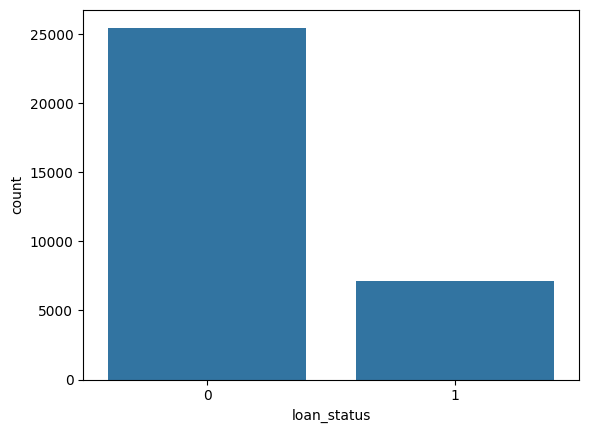

In [8]:
sns.countplot(x='loan_status',data=df)

# Outlier Check


*   Look for values that seem impossible, like age 144.
*   These are signs of bad data entries.



In [9]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


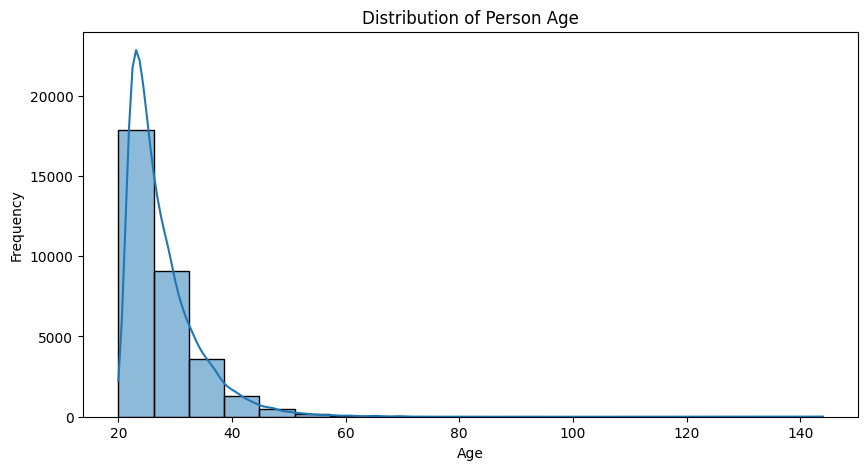

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(df['person_age'], bins=20, kde=True)
#smooth distribution curve (KDE) over the histogram

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Person Age')

plt.show()

In [11]:
(df['person_age']>80).sum()

np.int64(7)

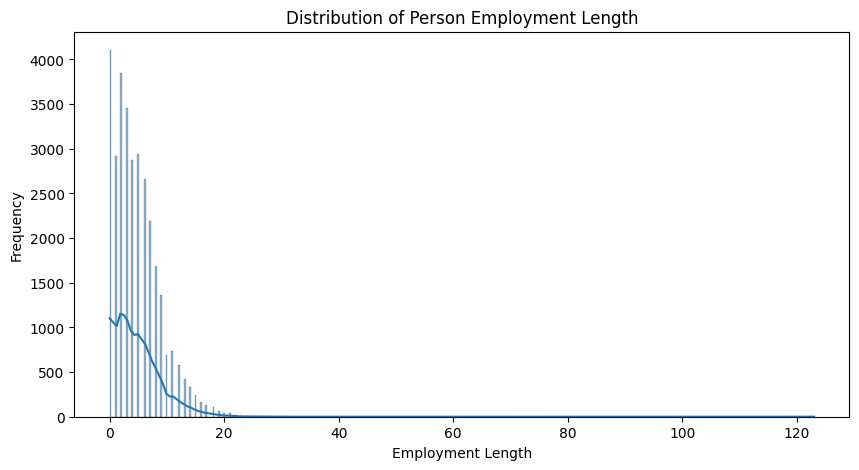

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(df['person_emp_length'], kde=True)

plt.xlabel('Employment Length')
plt.ylabel('Frequency')
plt.title('Distribution of Person Employment Length')

plt.show()

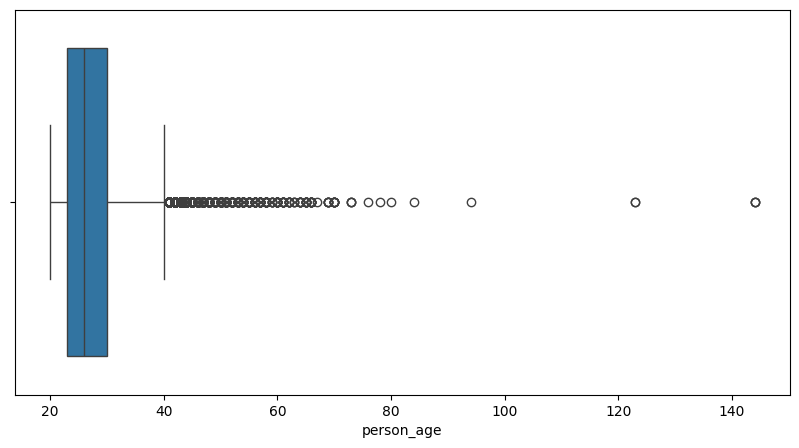

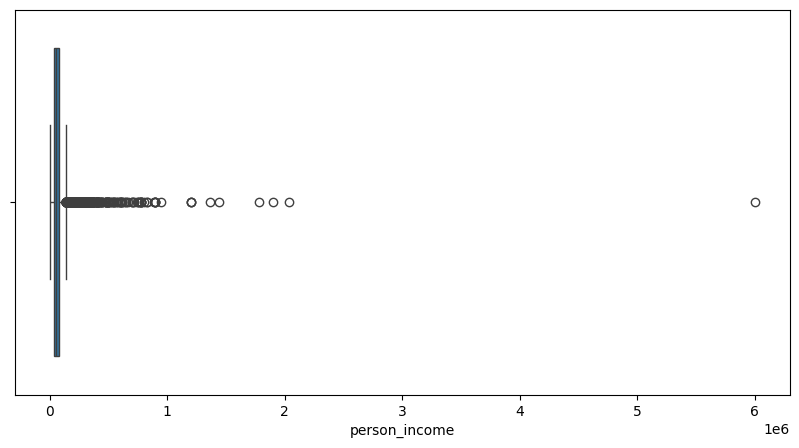

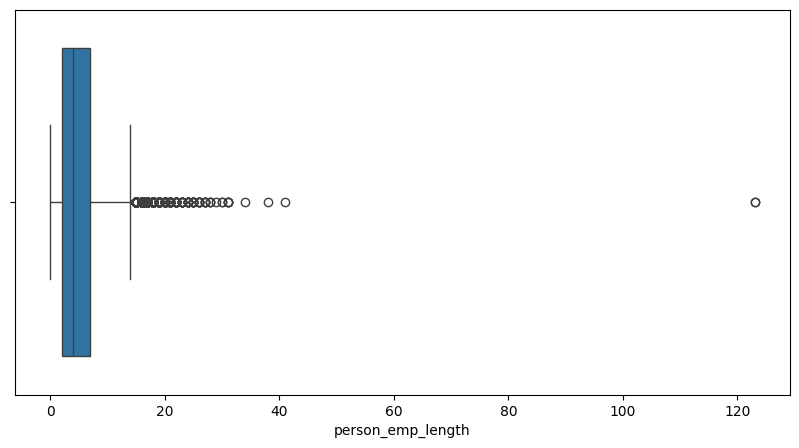

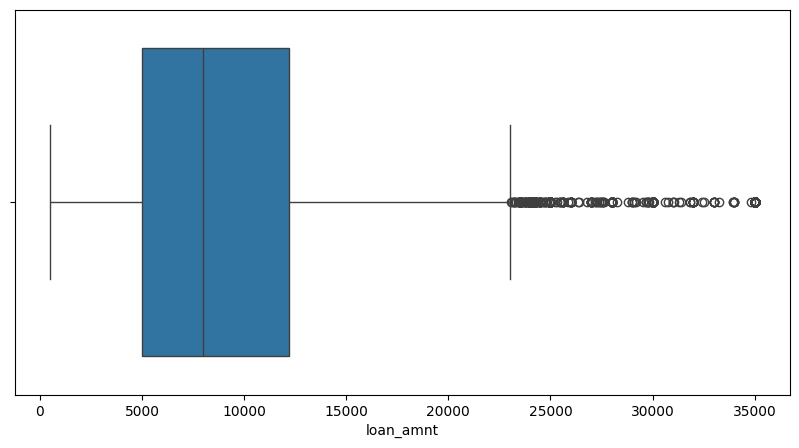

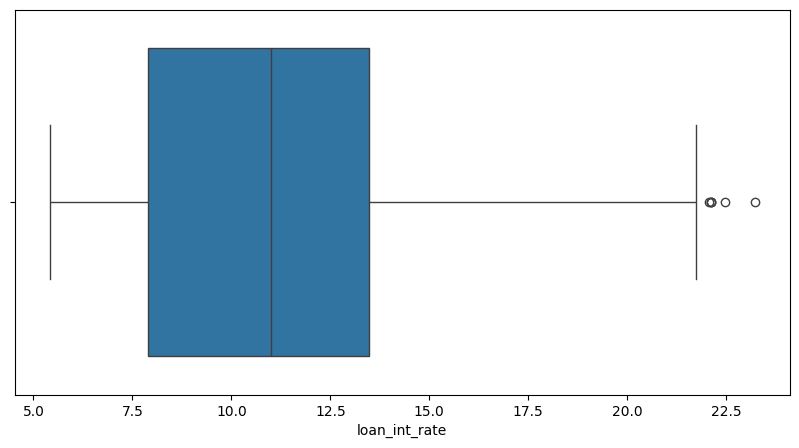

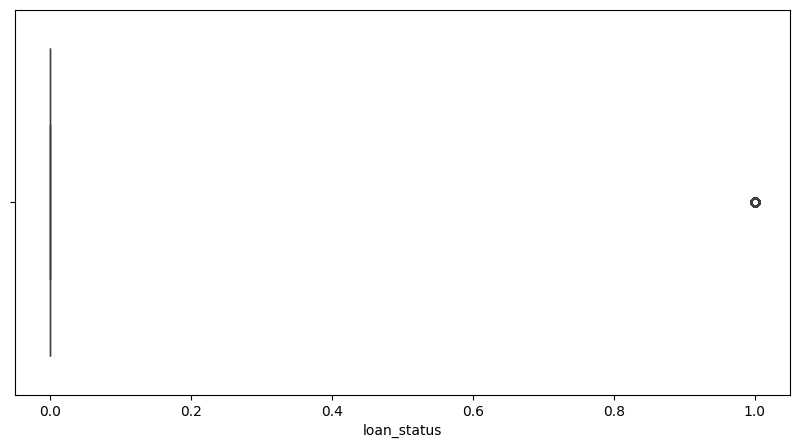

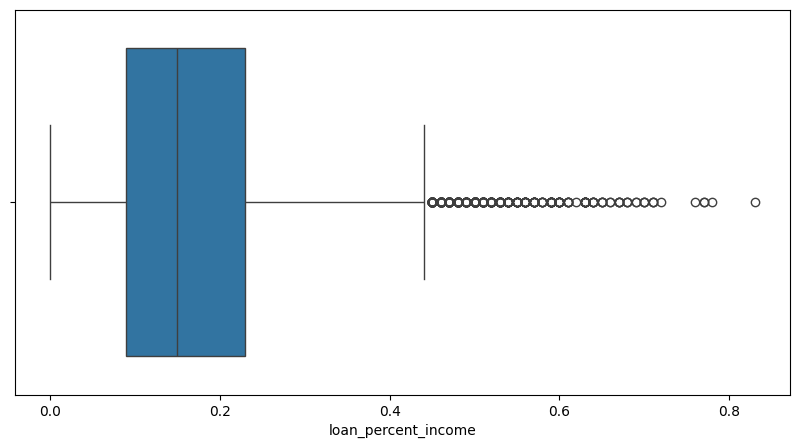

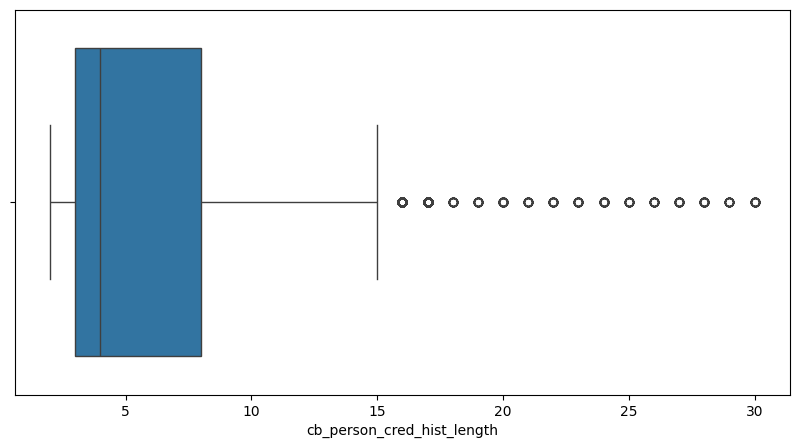

In [13]:
num_col = df.select_dtypes(include=np.number).columns #selecting the numerical coumns only

for col in num_col:
  plt.figure(figsize=(10,5))
  sns.boxplot(x=df[col])
  plt.show()

# Correlation Check


*   See how strongly features are related to each other.
*   This helps us spot repeated or linked information.



<Axes: >

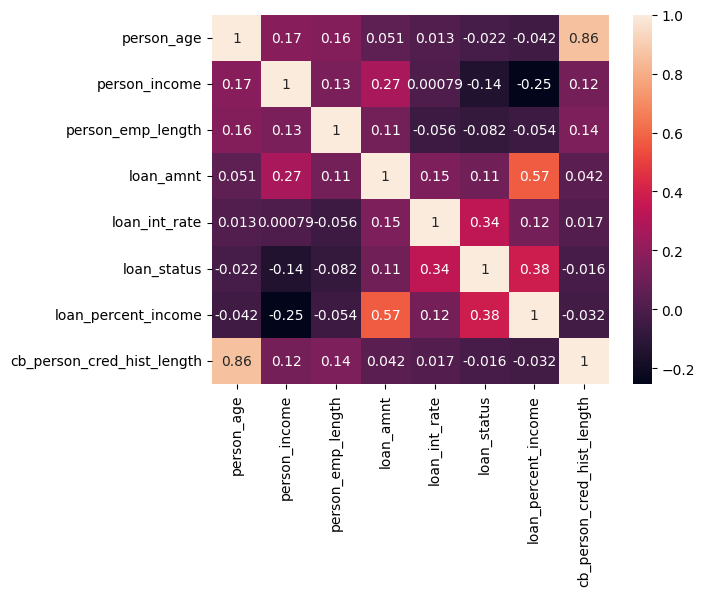

In [14]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

## Data Validation & cleaning

Here we clean and validate the data properly.

- Remove duplicate rows.
- Remove rows with impossible values for age or work experience.
- Check whether interest rates fall within a realistic range.
- Flag rows where related numerical values do not add up or are logically inconsistent.

In [15]:
# orginal rows and coumns
df.shape

(32581, 12)

In [16]:
df.duplicated().sum() # duplicated values

np.int64(165)

In [17]:
df.drop_duplicates(inplace=True) # removing duplicated values
print(f"number of rows after removing duplicate values = {df.shape[0]}")

number of rows after removing duplicate values = 32416


In [18]:
# Remove the Age below 18 and above 100
df = df[(df['person_age'] >= 18) & (df['person_age'] < 100)]

In [19]:
#Remove employment length greater than age or extreme outliers (>60)
df = df[df['person_emp_length']< df['person_age']]
df = df[df['person_emp_length']< 60]

## Features, Target & Train-Test Split

- Separate the dataset into input features (`X`) and the target variable (`y`).
- The target represents whether the applicant defaulted or not.
- Split the data into a training set and a testing set.
- The model learns only from the training set.
- The testing set is kept separate and used later to evaluate how well the model performs on unseen data.

In [20]:
x =df.drop('loan_status',axis=1)
y =df['loan_status']

In [21]:
#Train-Test Split
from sklearn.model_selection import train_test_split
x_train , x_test , y_train , y_test = train_test_split(x,y,test_size=0.2,random_state=42, stratify=y)

# test_size=0.2 → 80% of the data is used for training and 20% for testing.
# random_state=42 → Keeps the split the same every time we run the code.
# stratify=y → Keeps the same proportion of 0s and 1s in both training and testing data.

In [22]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                     'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']

## Handle Class Imbalance

- In this dataset, only a small number of applicants may actually default.
- This creates a **class imbalance**, where non-defaulters are much more common than defaulters.
- If we ignore this imbalance, the model may become biased toward the majority class.
- We give more importance to the minority class during model training.
- This helps the model learn to identify potential defaulters instead of simply predicting the majority class.

In [23]:
y_train.value_counts()

,count
loan_status,
0,19772
1,5445


In [24]:
#0 -> no loan (most)
#1 -> yes loan

no , yes = np.bincount(y_train)
# bincount creates bin for 0 & 1 and counts their values (same result as above value_count)
scale_weight = no / yes
# class weight is used to solve the class imbalanced problem
print(scale_weight)

3.6312213039485766


## Data Preprocessing — Pipeline & ColumnTransformer

- Raw data needs preprocessing before training.
- **Pipeline** combines preprocessing steps + model.
- **ColumnTransformer** applies different steps to different columns.
- Numeric → Scaling
- Categorical → Encoding

**Pipeline:** steps in order  
**ColumnTransformer:** different steps for different columns

### Preprocessing for Logistic Regression

- Fill missing numeric values.
- Scale numeric features.
- One-hot encode categorical features.

In [25]:
# logistic Regresseion : imputer + standarscalar, imputer + one-hot encoding
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [26]:
preprocessor_logistic = ColumnTransformer(
    transformers=[

        # Pipeline for numerical columns
        ('num', Pipeline(steps=[
            # Fill missing values with the median
            ('imputer', SimpleImputer(strategy='median')),

            # Scale values to a similar range
            ('scaler', StandardScaler())
        ]), numeric_cols),


        # Pipeline for categorical columns
        ('cat', Pipeline(steps=[
            # Replace missing values with "Missing"
            ('imputer', SimpleImputer(
                strategy='constant',
                fill_value='Missing'
            )),

            # Convert categories into numbers using one-hot encoding
            # Ignore new categories during prediction
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

### Preprocessing for XGBoost

- Fill missing numeric values.
- No scaling needed because tree models are not sensitive to feature scale.
- One-hot encode categorical columns.

In [27]:
#XGBoost: Impute numeric only (No Scaling), impute + One - Hot Encoding

preprocessor_xgboost = ColumnTransformer(
    transformers=[

        # Pipeline for numerical columns
        ('num', Pipeline(steps=[
            # Fill missing values with the median
            ('imputer', SimpleImputer(strategy='median'))
        ]), numeric_cols),

        # Pipeline for categorical columns
        ('cat', Pipeline(steps=[
            # Replace missing values with "Missing"
            ('imputer', SimpleImputer(
                strategy='constant',
                fill_value='Missing'
            )),

            # Convert categories into numbers using one-hot encoding
            # Ignore new categories during prediction
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

## Stratified Cross-Validation

- One train-test split may not give a reliable score.
- Split the training data into **k folds**.
- Each fold keeps a similar **default vs repaid ratio**.
- Train and evaluate the model on each fold.
- Compare the scores across all folds.

In [28]:
from sklearn.model_selection import StratifiedKFold , cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

cv= StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Metrics to calculate during cross-validation
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}


# Logistic Regression Pipeline

### Logistic Regression Parameters

- `class_weight='balanced'` → Gives more importance to the minority class (`Default`) when classes are imbalanced.
- `max_iter=1000` → Allows the model up to 1000 iterations to find the best solution.
- `random_state=42` → Makes the results reproducible.

In [29]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_logistic),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
logistic_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

# XGBoost Pipeline

### XGBoost Parameters

- `max_depth=5` → Controls how deep each tree can grow.

- `learning_rate=0.1` → Controls how much each new tree contributes.
- `n_estimators=100` → Number of trees in the model.
- `scale_pos_weight=scale_weight` → Gives more importance to the minority class.
- `random_state=42` → Keeps results reproducible.
- `n_jobs=-1` → Uses all available CPU cores to train faster.
(-1 means use all available cores.)

In [30]:
from xgboost import XGBClassifier

xgboost_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_xgboost),
    ('classifier', XGBClassifier( max_depth=5,
        learning_rate=0.1,
        n_estimators=300,
        scale_pos_weight= scale_weight,
        random_state=42,
        n_jobs =-1))
])
xgboost_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

## Cross-Validation Model Training & Evaluation

- Train and evaluate each model using 5-fold stratified cross-validation.
- Each model is trained multiple times using different training/validation folds.
- Calculate Accuracy, Precision, Recall, F1, and ROC-AUC for each fold.
- Average the scores to compare model performance.
- Use the results to help select the final model.

In [31]:
# Train and evaluate each model using cross-validation
for cv_name, pipe in [
    ("Logistic Regression", logistic_pipeline),
    ("XGBoost", xgboost_pipeline)
]:

    cv_results = cross_validate(
        pipe,
        x_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    print(cv_name)
    print(f"ROC-AUC : {cv_results['test_roc_auc'].mean():.4f}")
    print(f"Accuracy : {cv_results['test_accuracy'].mean():.4f}")
    print(f"Precision : {cv_results['test_precision'].mean():.4f}")
    print(f"Recall : {cv_results['test_recall'].mean():.4f}")
    print(f"F1 : {cv_results['test_f1'].mean():.4f}")
    print()

Logistic Regression
ROC-AUC : 0.8705
Accuracy : 0.8116
Precision : 0.5448
Recall : 0.7781
F1 : 0.6408

XGBoost
ROC-AUC : 0.9471
Accuracy : 0.9180
Precision : 0.8191
Recall : 0.7963
F1 : 0.8073



## Baseline Model — Logistic Regression

- Start with a simple Logistic Regression model.
- Use it as a benchmark for other models.
- Train it on the training data.
- Evaluate its performance on the test data.

In [32]:
baseline_model = logistic_pipeline.fit(x_train, y_train)

## XGBoost Hyperparameter Tuning

- Move from the baseline model to XGBoost.
- Hyperparameters are settings that control how the model learns.
- Test different combinations to find the best settings.
- Use cross-validation to compare each combination reliably.

In [33]:
xgboost_model = xgboost_pipeline.fit(x_train, y_train)

## Evaluation Helper Function

- Create one function to evaluate any model.
- Calculate accuracy, precision, recall, F1, and ROC-AUC.
- Display the confusion matrix.
- Display the precision-recall curve.

### Metrics

- `Accuracy` → How many predictions were correct.
- `Precision` → How many predicted defaulters were actually defaulters.
- `Recall` → How many actual defaulters the model found.
- `F1` → Overall balance between Precision and Recall.
- `ROC-AUC` → How well the model separates defaulters from non-defaulters.

### Report and Graph

- `Confusion Matrix` → Shows correct and wrong predictions.
- `Classification Report` → Shows Precision, Recall, and F1 for each class.
- `ROC Curve` → Shows model performance at different decision thresholds.
- `Precision-Recall Curve` → Shows the balance between finding defaulters and avoiding false alarms.

In [34]:
from sklearn.metrics import (
    confusion_matrix, classification_report,
    precision_recall_curve, roc_curve,
    accuracy_score, precision_score,
    recall_score, f1_score,
    roc_auc_score
)

def evaluate_model(model_name, model, x_test, y_test , threshold = None):

    # Make predictions on the test data
    #y_pred = model.predict(x_test)

    # Get probability of the positive class (Default)
    y_pred_proba = model.predict_proba(x_test)[:, 1]

    if threshold:
    # Use our chosen threshold to decide the final class
    # If probability >= threshold → predict 1 (Default)
    # If probability < threshold → predict 0 (Repaid)
      y_pred = (y_pred_proba >= threshold).astype(int)

    else:
    # If no threshold is given, use the model's default threshold
      y_pred = model.predict(x_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    # Display evaluation results
    print("=" * 60)
    print(f"Model: {model_name}")
    print("=" * 60)
    print(f"Threshold: {threshold}")
    print(f"Accuracy:  {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall:    {recall:.2f}")
    print(f"F1 Score:  {f1:.2f}")
    print(f"ROC-AUC:   {roc_auc:.2f}")
    print()

    # Display classification report
    print(f"{model_name} Classification Report:")
    print(classification_report(y_test, y_pred))

    # Calculate confusion matrix
    conf_matrix = confusion_matrix(y_test, y_pred)

    # Calculate ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

    # Calculate Precision-Recall curve
    pr_precision, pr_recall, _ = precision_recall_curve(
        y_test,
        y_pred_proba
    )

    # Create evaluation dashboard
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(14, 10)
    )

    fig.suptitle(
        f"{model_name} - Model Evaluation",
        fontsize=18,
        fontweight="bold"
    )

    # Confusion Matrix
    annot = [
        [f"TN\n{conf_matrix[0, 0]}", f"FP\n{conf_matrix[0, 1]}"],
        [f"FN\n{conf_matrix[1, 0]}", f"TP\n{conf_matrix[1, 1]}"]
    ]

    sns.heatmap(
        conf_matrix,
        annot=annot,
        fmt="",
        cmap="Blues",
        cbar=False,
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        annot_kws={"size": 13},
        ax=axes[0, 0]
    )

    axes[0, 0].set_title("Confusion Matrix", fontsize=14, pad=12)
    axes[0, 0].set_xlabel("Predicted")
    axes[0, 0].set_ylabel("Actual")

    # ROC Curve
    axes[0, 1].plot(
        fpr,
        tpr,
        lw=2,
        label=f"ROC-AUC = {roc_auc:.2f}"
    )

    axes[0, 1].plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        lw=1
    )

    axes[0, 1].set_title("ROC Curve", fontsize=14, pad=12)
    axes[0, 1].set_xlabel("False Positive Rate")
    axes[0, 1].set_ylabel("True Positive Rate")
    axes[0, 1].legend(loc="lower right")
    axes[0, 1].grid(alpha=0.2)

    # Precision-Recall Curve
    axes[1, 0].plot(
        pr_recall,
        pr_precision,
        lw=2
    )

    axes[1, 0].set_title(
        "Precision-Recall Curve",
        fontsize=14,
        pad=12
    )

    axes[1, 0].set_xlabel("Recall")
    axes[1, 0].set_ylabel("Precision")
    axes[1, 0].grid(alpha=0.2)

    # Metric Summary
    metrics = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }

    axes[1, 1].bar(
        metrics.keys(),
        metrics.values()
    )

    axes[1, 1].set_title(
        "Performance Metrics",
        fontsize=14,
        pad=12
    )

    axes[1, 1].set_ylabel("Score")
    axes[1, 1].set_ylim(0, 1)
    axes[1, 1].tick_params(axis="x", rotation=30)
    axes[1, 1].grid(axis="y", alpha=0.2)

    # Add metric values
    for i, value in enumerate(metrics.values()):
        axes[1, 1].text(
            i,
            value + 0.02,
            f"{value:.2f}",
            ha="center",
            fontsize=10
        )

    # Fix spacing between plots
    plt.subplots_adjust(
        top=0.90,
        bottom=0.10,
        left=0.08,
        right=0.95,
        hspace=0.35,
        wspace=0.25
    )

    plt.show()

# Evaluate the Logistic Model

Model: Logistic Regression
Threshold: None
Accuracy:  0.82
Precision: 0.56
Recall:    0.79
F1 Score:  0.65
ROC-AUC:   0.88

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305



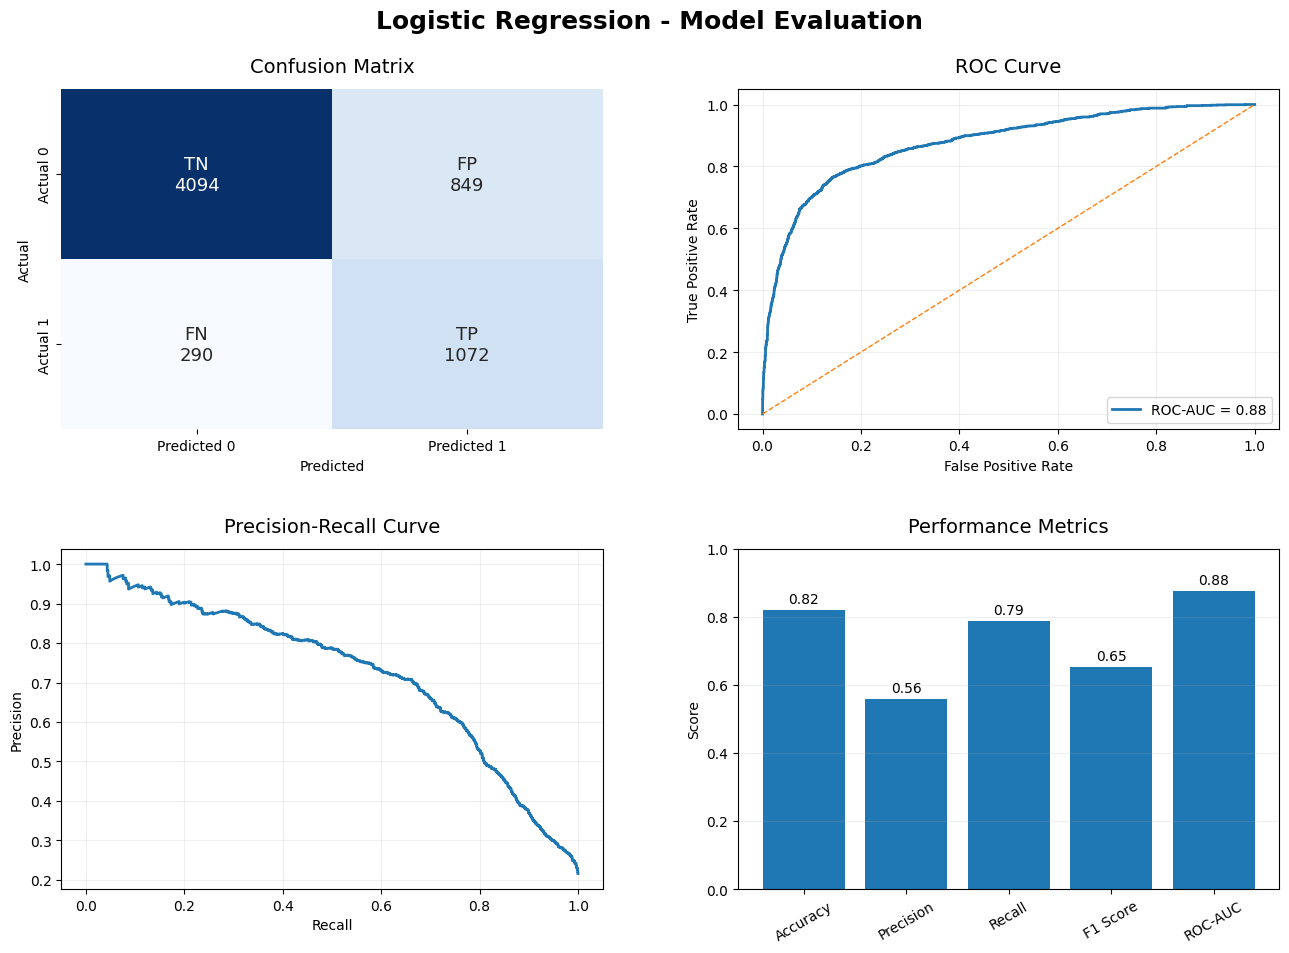

In [35]:
evaluate_model("Logistic Regression", baseline_model, x_test, y_test)

# Evalutate the XGBoost Model

Model: XGBoost Model
Threshold: None
Accuracy:  0.92
Precision: 0.82
Recall:    0.81
F1 Score:  0.81
ROC-AUC:   0.95

XGBoost Model Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.82      0.81      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305



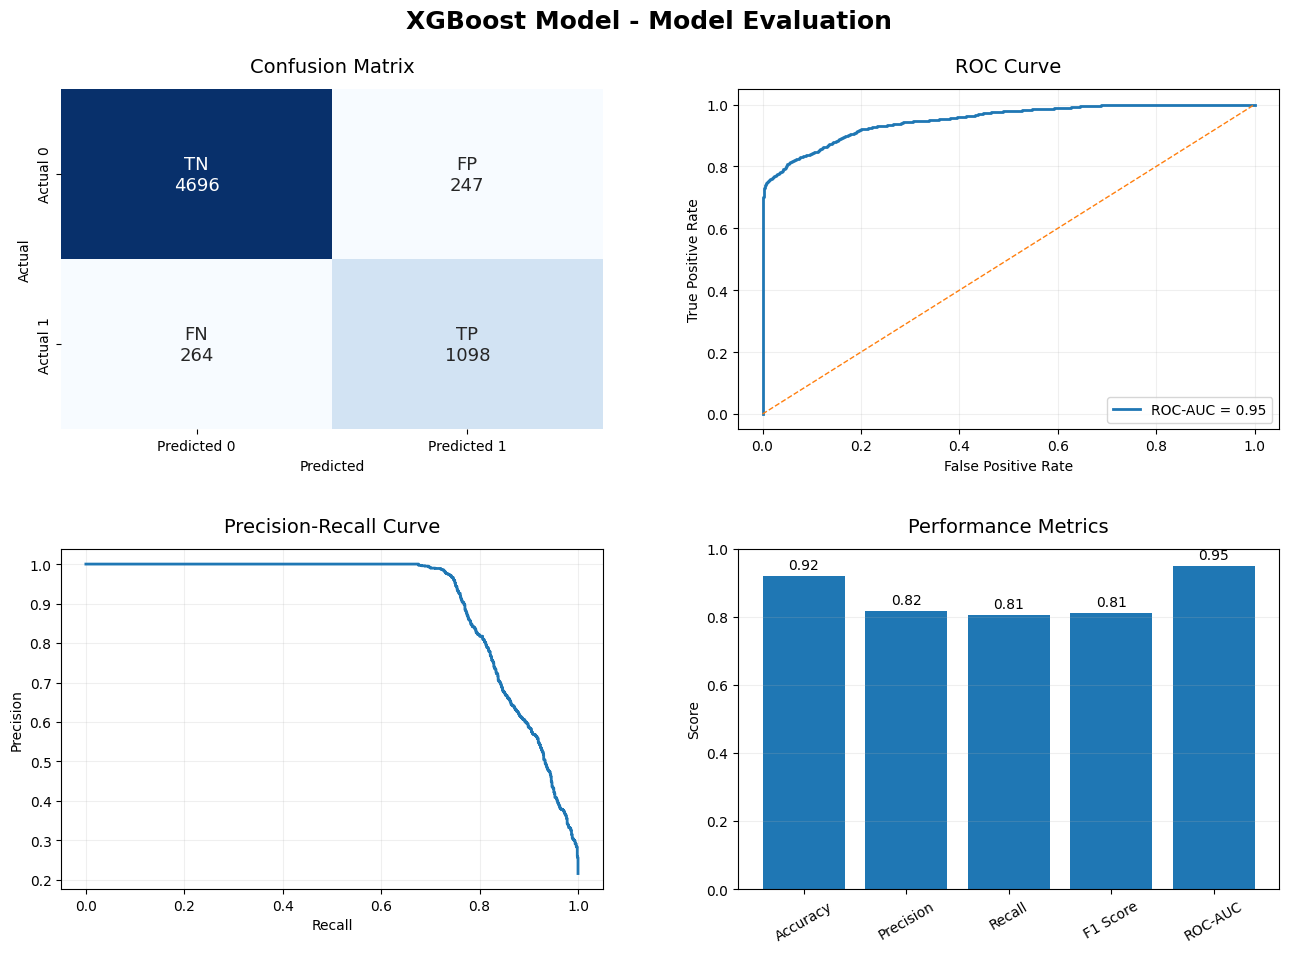

In [36]:
evaluate_model("XGBoost Model", xgboost_model, x_test, y_test)

## XGBoost Hyperparameter Tuning

- Now we improve the XGBoost model by tuning its hyperparameters.
- Hyperparameters are settings that control how the model learns.
- We test different combinations of these settings to find the best one.
- Cross-validation is used to compare the combinations reliably.
- The best combination is selected based on the chosen evaluation metric.

In [37]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# Settings that RandomizedSearchCV will try
param_grid = {

    # Number of trees the model will build
    "classifier__n_estimators": randint(150, 600),

    # How deep each tree can grow
    "classifier__max_depth": randint(3, 10),

    # How much each new tree contributes to the model
    "classifier__learning_rate": uniform(0.01, 0.5),

    # How many rows are randomly used for each tree
    "classifier__subsample": uniform(0.6, 0.4),

    # How many columns/features are randomly used for each tree
    "classifier__colsample_bytree": uniform(0.6, 0.4),

    # How much evidence is needed before creating a new branch
    "classifier__min_child_weight": randint(1, 10),

    # How much improvement is needed before making a new split
    "classifier__gamma": uniform(0, 5)
}

# Lower gamma → easier to make splits → more complex trees → higher overfitting risk
# Higher gamma → harder to make splits → simpler trees → lower overfitting risk

In [38]:
xgboost_tuned_model = RandomizedSearchCV(
    xgboost_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

xgboost_tuned_model.fit(x_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b63e01f8a50>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b63e0efc980>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7b63e01f8690>},
                   scoring='average_precision', verbose=1)

In [39]:
xgboost_tuned_model.best_params_

{'classifier__colsample_bytree': np.float64(0.8192334501724055),
 'classifier__gamma': np.float64(0.9841984267958748),
 'classifier__learning_rate': np.float64(0.07733435286787237),
 'classifier__max_depth': 9,
 'classifier__min_child_weight': 4,
 'classifier__n_estimators': 264,
 'classifier__subsample': np.float64(0.9508112153145531)}

In [40]:
xgboost_tuned_model.best_score_

np.float64(0.9030193817315755)

Model: XGBoost
Threshold: None
Accuracy:  0.93
Precision: 0.87
Recall:    0.79
F1 Score:  0.83
ROC-AUC:   0.95

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      4943
           1       0.87      0.79      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.91      0.88      0.89      6305
weighted avg       0.93      0.93      0.93      6305



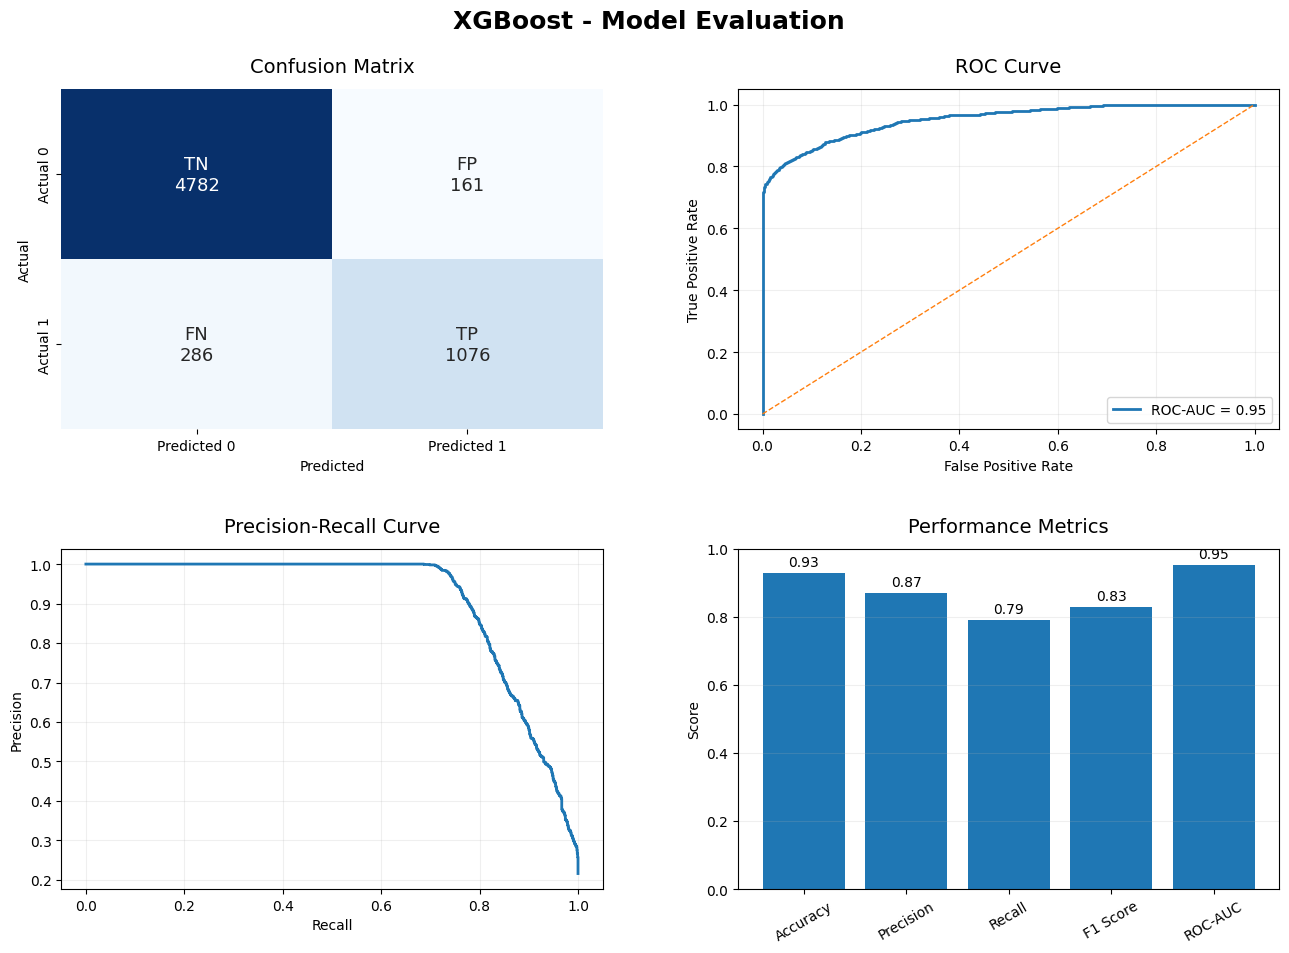

In [41]:
evaluate_model("XGBoost", xgboost_tuned_model, x_test , y_test)

##  Optimizing the Classification Threshold

- The model gives a probability, not a direct `0` or `1`.
- We choose a cut-off point called the **threshold**.
- Above the threshold → `1 (Default)`, below it → `0 (Repaid)`.
- We test different thresholds and choose the one that gives the best result.

Model: XGBoost
Threshold: 0.7114397883415222
Accuracy:  0.94
Precision: 0.97
Recall:    0.75
F1 Score:  0.84
ROC-AUC:   0.95

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.97      0.75      0.84      1362

    accuracy                           0.94      6305
   macro avg       0.95      0.87      0.90      6305
weighted avg       0.94      0.94      0.94      6305



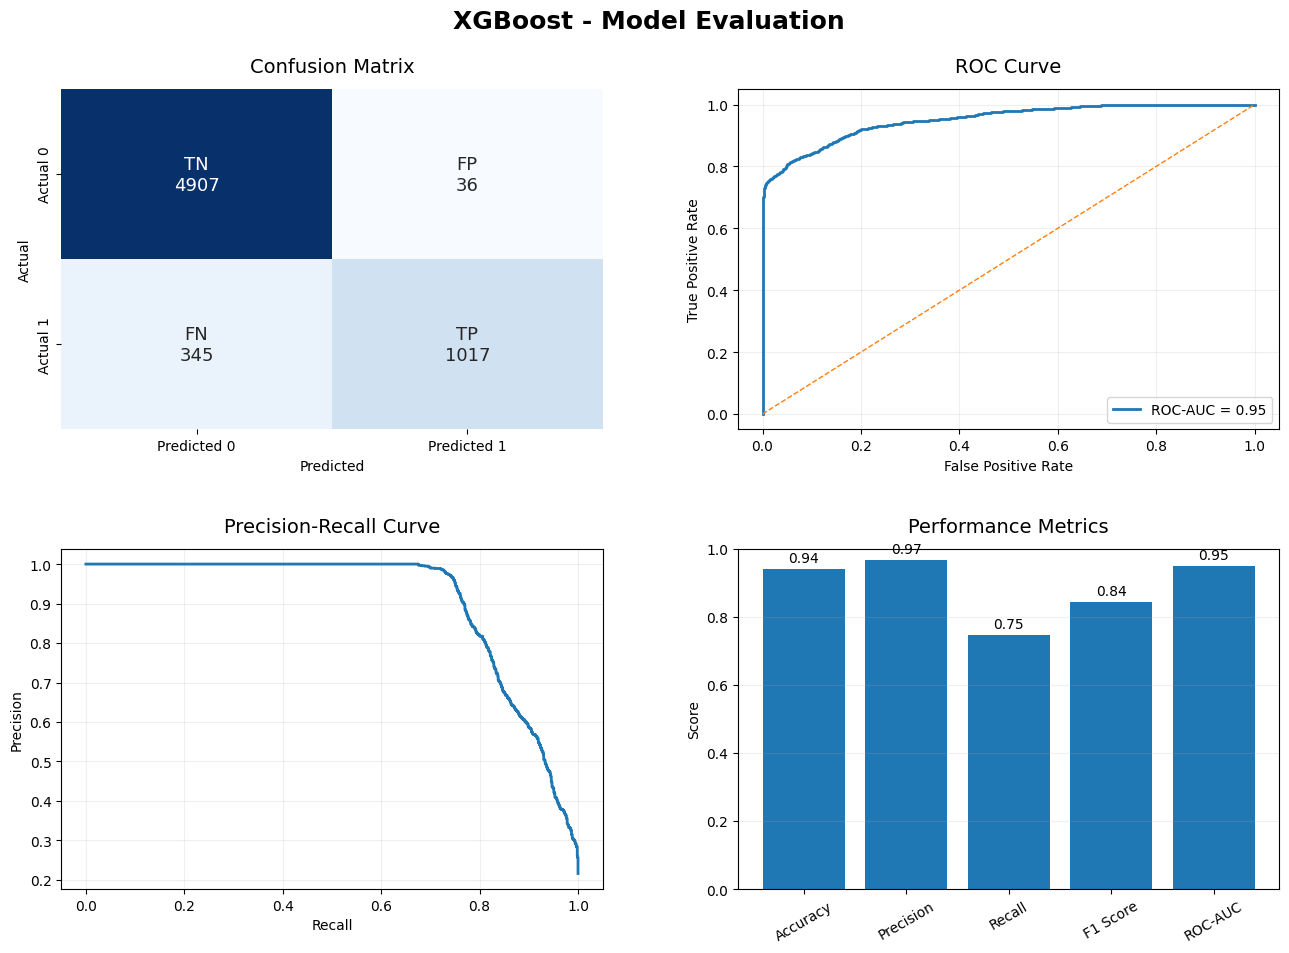

In [42]:
# Get the probability of class 1 (Default) from XGBoost
prob = xgboost_model.predict_proba(x_test)[:, 1]

# Try many different thresholds
# For each threshold, calculate Precision and Recall
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)

# Calculate F1 score for each threshold
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# Find the position of the highest F1 score
best = np.argmax(f1[:-1])

# Get the threshold that gave the highest F1 score
best_threshold = thresholds[best]

# Evaluate XGBoost using the best threshold instead of the default 0.5
evaluate_model( "XGBoost", xgboost_model, x_test, y_test, best_threshold )

## Probability Calibration

- Sometimes a model's predicted probability is not realistic.
- For example, a `30%` risk should mean about a `30%` chance of Default.
- We use a calibration plot to check this.
- If the probabilities are off, we can calibrate the model.

## Methods to Fix **Poorly** Calibrated Probabilities

1. **Platt Scaling / Sigmoid** → Adjusts the model's probabilities using a sigmoid function.
2. **Isotonic Regression** → Learns a flexible relationship to make the predicted probabilities more accurate.
3. **Temperature Scaling** → Adjusts the confidence of neural networks to make their probabilities more reliable.

In [43]:
#1 . Calibrated XGBoost model
from sklearn.calibration import CalibratedClassifierCV , calibration_curve

best_model = xgboost_tuned_model.best_estimator_
calibrated_xgboost = CalibratedClassifierCV(
    xgboost_tuned_model,
    cv=cv,
    method="sigmoid"
)

calibrated_xgboost.fit(x_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits
Fitting 5 folds for each of 150 candidates, totalling 750 fits
Fitting 5 folds for each of 150 candidates, totalling 750 fits
Fitting 5 folds for each of 150 candidates, totalling 750 fits
Fitting 5 folds for each of 150 candidates, totalling 750 fits


CalibratedClassifierCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                       estimator=RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                                                    estimator=Pipeline(steps=[('preprocessor',
                                                                               ColumnTransformer(transformers=[('num',
                                                                                                                Pipeline(steps=[('imputer',
                                                                                                                                 SimpleImputer(strategy='median'))]),
                                                                                                                ['person_age',
                                                                                                                 'person_income',
                                                                                                                 'per...
                                                                         'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b63e01f8a50>,
                                                                         'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b63e0efc980>,
                                                                         'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7b63e01f8690>},
                                                    scoring='average_precision',
                                                    verbose=1))

In [44]:
#2. Get probabilities
uncalibrated = xgboost_model.predict_proba(x_test)[:, 1]
calibrated = calibrated_xgboost.predict_proba(x_test)[:, 1]

In [45]:
uncalibrated

array([0.9528101 , 0.19060071, 0.9843725 , ..., 0.61099994, 0.09072538,
       0.01656131], dtype=float32)

In [46]:
calibrated

array([0.51461649, 0.02912173, 0.95066825, ..., 0.39831904, 0.02498716,
       0.01341876])

In [47]:
#3. create a calibration curves
actual_uncal , predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)
actual_cal , predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

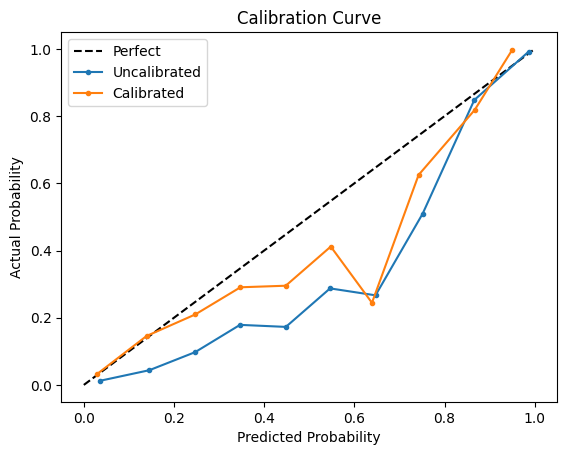

In [48]:
#4. plot the curve
plt.plot( [0,1], [0,1], 'k--' , label='Perfect')
plt.plot(predicted_uncal, actual_uncal, marker=".", label="Uncalibrated")
plt.plot(predicted_cal, actual_cal, marker=".", label="Calibrated")
plt.legend()
plt.xlabel("Predicted Probability")
plt.ylabel("Actual Probability")
plt.title("Calibration Curve")
plt.show()

# Get probability from the calibrated model

In [66]:
from sklearn.metrics import precision_recall_curve

#1. Get probability from the calibrated model , not the old xgboost_model
calibrated_prob = calibrated_xgboost.predict_proba(x_test)[:, 1]

#2. Calculate precision and recall for different thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_prob)

#3. Find the position of the highest F1 score
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

print(f"Best threshold: {best_threshold}")

Best threshold: 0.6945177905974809


## SHAP Interpretation - Global & Local

- SHAP explains **why a model makes a prediction**.
- It shows which features **increase or decrease** the prediction.
- It is a way of explaining a "black box" model

In [67]:
#1 install and import the shap
import shap

In [68]:
#2. Get the trained XGBoost classifier model out of pipeline
xgboost_classifier = xgboost_model.named_steps['classifier']

In [69]:
#3. Transform X_test using the same preprocessing used for training.
x_test_transformed = xgboost_model.named_steps['preprocessor'].transform(x_test)

In [70]:
#4. Get feature names after one-hot encoding, so plots are readable
feature_names = xgboost_model.named_steps['preprocessor'].get_feature_names_out()

In [71]:
#5. Convert to a dataframe for cleaner SHAP plots
x_test_transformed_df = pd.DataFrame(x_test_transformed, columns=feature_names)

In [72]:
#6. Create SHAP explainer built for tree based model
explainer = shap.TreeExplainer(xgboost_classifier)

In [73]:
#7. Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(x_test_transformed_df)

### Global Explanation

- Shows which features are **most important to the model overall**.
- Helps us understand **what factors generally influence the model's predictions**.

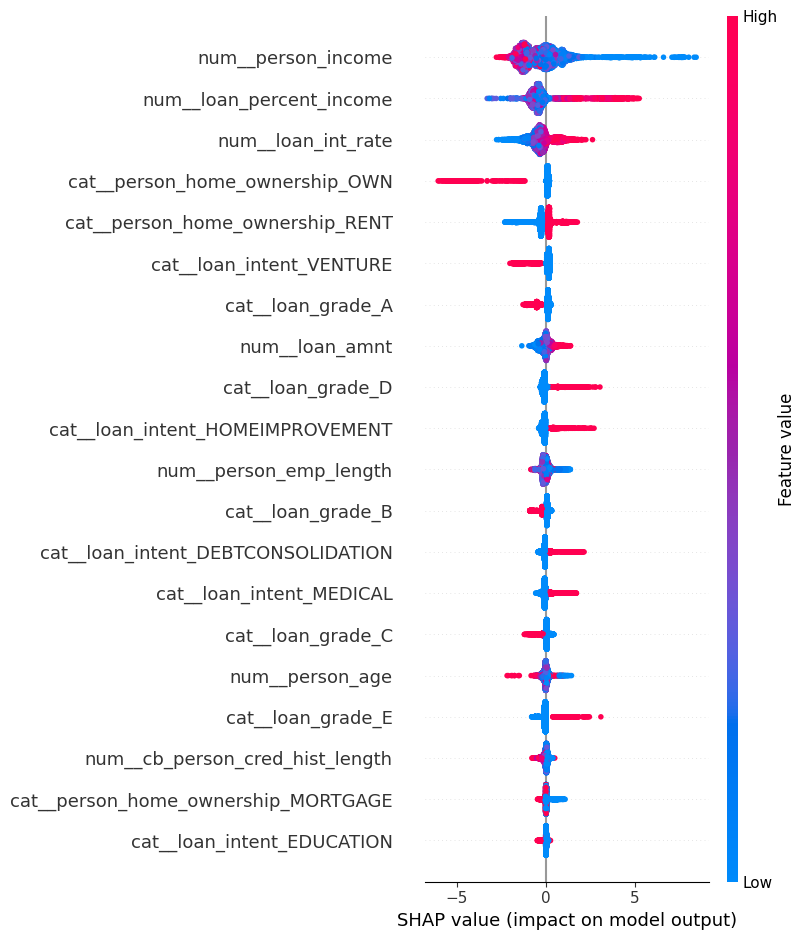

In [74]:
shap.summary_plot(shap_values, x_test_transformed_df)

### Local Explanation

- Explains **why the model made a prediction for one specific customer**.
- Shows which features **increased or decreased that customer's predicted risk**.

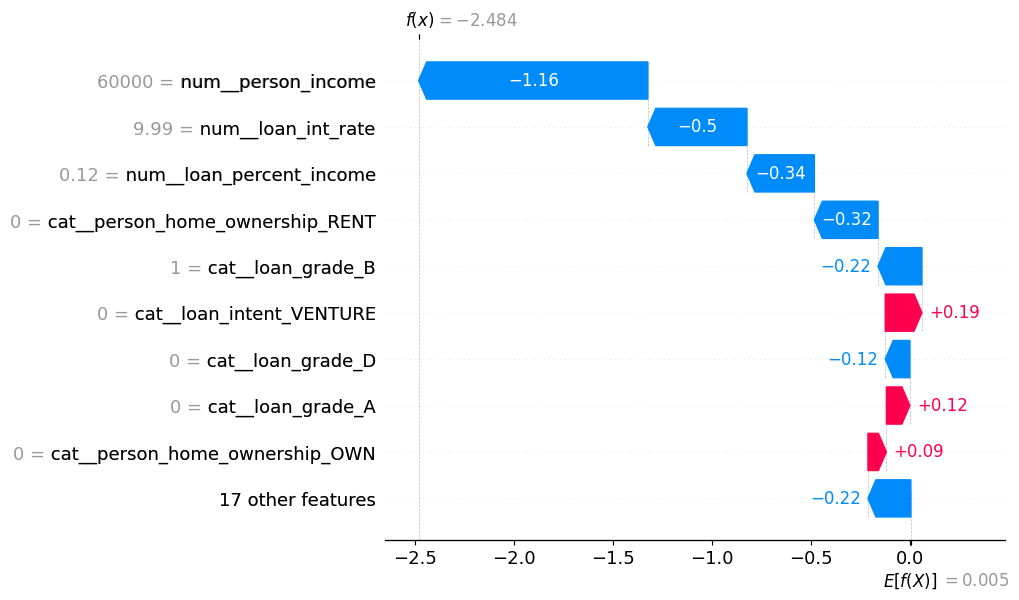

In [75]:
# 1. Pick one row to explain, e.g. the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down.
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = x_test_transformed_df.iloc[row_index],
        feature_names = feature_names
    )
)

# Save the model

In [76]:
import joblib
joblib.dump(calibrated_xgboost, "Credit_risk_model.pkl")
print("Model exported successfully")

Model exported successfully


In [77]:
best_threshold

np.float64(0.6945177905974809)

In [78]:
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']